In [1]:
import pandas as pd
import numpy as np
import torch

import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm

In [4]:
from sklearn.pipeline import Pipeline
from sklearn.multioutput import MultiOutputRegressor

from sklearn.metrics import (
    mean_absolute_percentage_error, 
    root_mean_squared_error
)

from sklearn.tree import DecisionTreeRegressor # CART
import xgboost as xgb # XGBoost
from sklearn.svm import SVR # SVR
from sklearn.neural_network import MLPRegressor # MLP

In [5]:
import sti_toolkit as sti
import dataset as ds

# Define global variables

In [6]:
NO_DATA_VALUE = -9999

VI_BANDS_NAMES = ['NDVI', 'BNDVI', 'GNDVI', 'GBNDVI', 'GRNDVI', 'RBNDVI']

WB_WEATHER_BANDS_NAMES = [
    'min T', 'mean T', 'T', 'max T',
    'min rel. hum.', 'mean rel. hum.', 'rel. hum.', 'max rel. hum.',
    'min pressure', 'mean pressure', 'max pressure',
    'max gust', 'wind direction', 'wind speed',
    'precipitation', 'global energy'
]

SPECTRAL_BANDS_NAMES, WB_WEATHER_BANDS_RS_NAMES = [
    'NIR', 'R', 'G', 'B', *VI_BANDS_NAMES
], [
    f'{band}; T{time}' for band, time in np.array(
        np.meshgrid(WB_WEATHER_BANDS_NAMES, ['0', '8', '16'])
    ).T.reshape(-1, 2)
]

ALL_FEATURES = [*SPECTRAL_BANDS_NAMES, *WB_WEATHER_BANDS_RS_NAMES]

# Error metrics

In [7]:
def smape_pure(actual, forecast, handle_zeros='zero'):
    if len(actual) != len(forecast):
        raise ValueError("Lengths must match")
    
    errors = []
    for a, f in zip(actual, forecast):
        denom = (abs(a) + abs(f)) / 2
        if denom == 0:
            if handle_zeros == 'zero':
                errors.append(0.0)
            elif handle_zeros == 'raise':
                raise ValueError("Zero denominator encountered")
            # 'exclude' skips automatically
        else:
            errors.append(abs(a - f) / denom)
            
    if not errors:
        raise ValueError("No valid points to compute SMAPE")
    return (sum(errors) / len(errors)) * 100

# Fertilization Data (Main Table)

In [8]:
N_BANDS = 18

patches_dataset_clean = pd.read_pickle(
    './data/pkl/'+\
    f'Targeted fertilization v3.patches_dataset.kernel=8_stride=1_bands={N_BANDS}.weather.land=Wheat_ph=2.v3.pkl'
)

In [9]:
# Parcel area statistics
patches_dataset_clean.loc[
    :,
    'Area (ha)'
].describe().round(2)

count    24.00
mean      6.22
std      11.47
min       0.53
25%       1.27
50%       2.16
75%       4.08
max      53.02
Name: Area (ha), dtype: float64

# Get train / dev / test images

In [10]:
gerk_train, gerk_dev, gerk_test = pd.read_pickle(
    f'./data/pkl/'
    f'Targeted fertilization v3.patches_dataset.kernel=8_stride=1_bands={N_BANDS}.weather.land=Wheat_ph=2.v3.train-dev-test-splits.pkl'
)

In [11]:
# Getting the correponding raster patches
patches_dataset_train_dev, patches_dataset_test = patches_dataset_clean.loc[
    pd.IndexSlice[[*gerk_train, *gerk_dev], :, :]
].copy(), patches_dataset_clean.loc[
    pd.IndexSlice[gerk_test, :, :]
].copy()

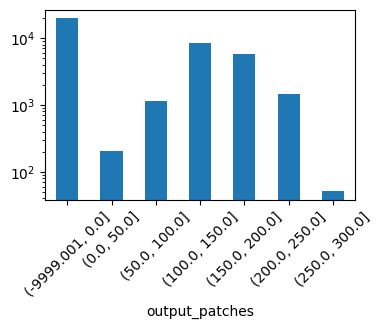

In [12]:
# ## Plotting the distribution of [mean] nitrogen per patch 
fig, ax = plt.subplots(1, 1, figsize=(4, 4/1.618))

out = pd.cut(
    patches_dataset_train_dev.output_patches.apply(
        lambda l: torch.mean(l.squeeze(0).squeeze(1), dim=(1,2)).numpy().tolist()
    ).explode(),
    bins=[NO_DATA_VALUE, 0, 50, 100, 150, 200, 250, 300], include_lowest=True
)
out.value_counts(sort=False).plot.bar(rot=45, ax=ax)
ax.set_yscale('log')

In [13]:
# ## Split Patches to Train/Dev sets (80%/20%), stratified by (discretized/binned) Ammonitrat quantity
patches_dataset_train, patches_dataset_dev = ds.train_test_split(
    patches_dataset_train_dev.explode(['input_patches', 'output_patches']).explode(['input_patches', 'output_patches']),
    test_size=0.2,
    random_state=3407,
    stratify=out
)

In [15]:
patches_dataset_train_th = ds.ITC_Patches(
    [arr.unsqueeze(0) for arr in patches_dataset_train.input_patches.values.tolist()], 
    [arr.unsqueeze(0) for arr in patches_dataset_train.output_patches.values.tolist()],
    augmentation = None
)
patches_dataset_dev_th = ds.ITC_Patches(
    [arr.unsqueeze(0) for arr in patches_dataset_dev.input_patches.values.tolist()], 
    [arr.unsqueeze(0) for arr in patches_dataset_dev.output_patches.values.tolist()], 
    transform = patches_dataset_train_th.transform,
    augmentation = None
)
patches_dataset_test_th = ds.ITC_Patches(
    [arr.squeeze(0) for arr in patches_dataset_test.input_patches.values.tolist()], 
    [arr.squeeze(0) for arr in patches_dataset_test.output_patches.values.tolist()], 
    transform = patches_dataset_train_th.transform,
    augmentation = None
)

In [16]:
X_train__standardizer = patches_dataset_train_th.transform

In [17]:
X_train, X_dev, X_test = (
    X_train__standardizer(patches_dataset_train_th.input) * patches_dataset_train_th.pixel_mask,
    X_train__standardizer(patches_dataset_dev_th.input) * patches_dataset_dev_th.pixel_mask,
    X_train__standardizer(patches_dataset_test_th.input) * patches_dataset_test_th.pixel_mask
)

y_train, y_dev, y_test = (
    patches_dataset_train_th.target * patches_dataset_train_th.pixel_mask,
    patches_dataset_dev_th.target * patches_dataset_dev_th.pixel_mask,
    patches_dataset_test_th.target * patches_dataset_test_th.pixel_mask
)

In [18]:
X_train_unfolded, X_dev_unfolded, X_test_unfolded = (
    X_train.flatten(start_dim=1, end_dim=-1),
    X_dev.flatten(start_dim=1, end_dim=-1),
    X_test.flatten(start_dim=1, end_dim=-1)
)

y_train_unfolded, y_dev_unfolded, y_test_unfolded = (
    y_train.flatten(start_dim=1, end_dim=-1),
    y_dev.flatten(start_dim=1, end_dim=-1),
    y_test.flatten(start_dim=1, end_dim=-1)
)

y_mask_train_unfolded, y_mask_dev_unfolded, y_mask_test_unfolded = (
    patches_dataset_train_th.pixel_mask.flatten(start_dim=1, end_dim=-1),
    patches_dataset_dev_th.pixel_mask.flatten(start_dim=1, end_dim=-1),
    patches_dataset_test_th.pixel_mask.flatten(start_dim=1, end_dim=-1)
)

In [19]:
X_train_unfolded.shape,\
X_dev_unfolded.shape,\
X_test_unfolded.shape

(torch.Size([21762, 1152]), torch.Size([5413, 1152]), torch.Size([5116, 1152]))

In [20]:
# Shuffle train samples 
train_ix = np.arange(len(X_train_unfolded))
np.random.shuffle(train_ix)

# Train ML baselines
### ...evaluate at the patch level.

In [ ]:
models = {

}
results = {
    'actual': y_test_unfolded
}


# From (Sajindra et al., 2024)...
model_params__dnn = dict(
    hidden_layer_sizes=(10, 10, 10, 10), 
    activation='tanh',                   
    solver='adam',
    max_iter=100,
    early_stopping=True,
    n_iter_no_change=10,
)

for model, model_params, name in zip(
    [DecisionTreeRegressor, xgb.XGBRegressor, SVR, MLPRegressor],
    [{}, {}, {}, model_params__dnn],
    ['CART', 'XGBoost', 'SVMr', 'MLP']
):

    if not issubclass(model, SVR):
        pipeline = Pipeline([
            (
                'model', model(**model_params)
            )
        ])
    else:
        pipeline = Pipeline([
            (
                'model', MultiOutputRegressor(
                    model(**model_params),
                    n_jobs=y_train_unfolded.shape[1]
                )
            )
        ])

    pipeline.fit(
        X_train_unfolded[train_ix], 
        y_train_unfolded[train_ix]
    )

    # Save model
    models[name] = pipeline

    # Save results 
    results[name] = (
        y_test_pred := pipeline.predict(
            X_test_unfolded
        )
    )

    # Output metrics
    print(
        f'''{name};\t\tRMSE: {float(
            root_mean_squared_error(
                y_test_unfolded[y_mask_test_unfolded], 
                y_test_pred[y_mask_test_unfolded]
            )
        ):.2f};\t\t'''+\
        f'''MAPE: {float(
            mean_absolute_percentage_error(
                y_test_unfolded[y_mask_test_unfolded], 
                y_test_pred[y_mask_test_unfolded]
            )*100
        ):.2f};\t\t'''+\
        f'''SMAPE: {float(
            smape_pure(
                y_test_unfolded[y_mask_test_unfolded], 
                y_test_pred[y_mask_test_unfolded]
            )
        ):.2f}'''
    )

In [ ]:
pd.Series(models).to_pickle(f'ML_in-channels={N_BANDS}_y_pred_ITC_test_set.v2_unfolded.models.pkl.gzip')
pd.Series(results).to_pickle(f'ML_in-channels={N_BANDS}_y_pred_ITC_test_set.v2_unfolded.results.pkl.gzip')

# Reconstructing images

In [21]:
models = pd.read_pickle(f'ML_in-channels={N_BANDS}_y_pred_ITC_test_set.v2_unfolded.models.pkl.gzip')

In [22]:
def baseline_model_inference(model, raster_data, data_transform, kernel, stride, no_data=-9999):
    model_output_mask = raster_data.output > 0
    model_output_shape = raster_data.output_patches.shape

    pred_patches = torch.tensor(
        model(
            data_transform(
                raster_data.input_patches.squeeze(0)
            ).flatten(
                start_dim=1, 
                end_dim=-1
            )
        )
    )    
    pred_patches = pred_patches.reshape(
        model_output_shape
    )

    pred_union = torch.nan_to_num(
        sti.unary_union(
            pred_patches,
            C=raster_data.output_patches_metadata['C'],
            H=raster_data.output_patches_metadata['H'],
            W=raster_data.output_patches_metadata['W'],
            kernel_size=kernel,
            stride=stride
        ),
        nan=no_data
    )
    pred_union[~model_output_mask] = no_data

    return pred_union

In [ ]:
for raster_data in patches_dataset_test.itertuples():
    raster_target_band = np.copy(raster_data.output)

    for model_name, model in models.items():
        raster_pred_band = np.copy(
            baseline_model_inference(
                model.predict, raster_data, X_train__standardizer, 8, 1
            )
        )
        
        np.save(f'{model_name}_in-channels={N_BANDS}_y_pred_gerk={raster_data.Index[0]}.npy', raster_pred_band)

# Visualizing results

In [ ]:
# ground_truth_ranges = torch.concatenate(
#     [
#         torch.tensor(
#             [
#                 [
#                     torch.min(tmp[tmp > 0]), 
#                     torch.max(tmp[tmp > 0])
#                 ]
#             ]
#         )
#         for tmp in patches_dataset_clean.loc[
#             :,
#             'output'
#         ].values
#     ]
# ).numpy()

# ground_truth_vmin, ground_truth_vmax = (
#     np.min(ground_truth_ranges[:, 0]), 
#     np.max(ground_truth_ranges[:, 1])
# )

In [23]:
y_test_models = {
    'actual': 'Ground truth',
    'SVMr': 'SVR',
    'CART': 'CART',
    'XGBoost': 'XGBoost',
    'MLP': 'MLP',
    'UNet': 'TerrAI'
}

# Selected parcel
mask = pd.IndexSlice[
    selected_parcel := gerk_test[0],
    :, 
    :
]

# Ground truth image
y_test_results = {
    'actual': np.copy(
        patches_dataset_clean.loc[mask, 'output'].values[0]
    ),
    **{
        k: np.load(f'{k}_in-channels={N_BANDS}_y_pred_gerk={selected_parcel}.npy')
        for k in list(y_test_models.keys())[1:]
    }
}

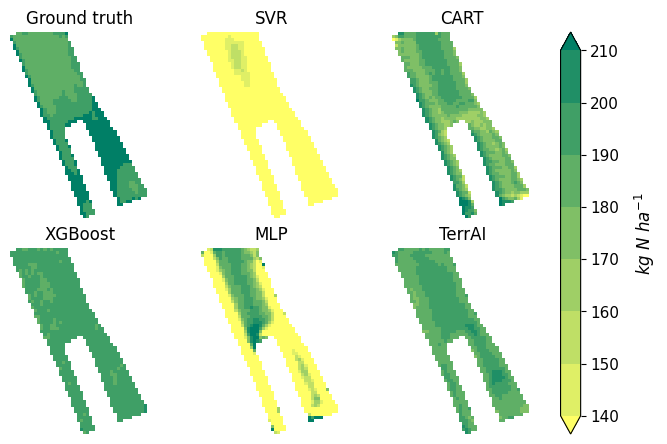

In [24]:
# # Define bin edges
# bounds = [0, *np.arange(ground_truth_vmin, ground_truth_vmax+1, 20), 340]
bounds = np.arange(140, 220, 10)

# Sample a built-in colormap into len(bounds)-1 discrete colors
cmap = plt.get_cmap("summer_r", len(bounds) - 1 + 2)
norm = BoundaryNorm(bounds, ncolors=cmap.N, extend='both')

fig, ax = plt.subplots(2, 3, figsize=(7, 7/1.618), sharex=True, sharey=True, constrained_layout=True)


for (ax_i, (y_test_model, ax_i_title)) in zip(
    ax.flatten(),
    y_test_models.items(),
):
    # Title
    ax_i.set_title(ax_i_title)
    ax_i.set_axis_off()

    # Image
    y_test_result = np.copy(y_test_results[y_test_model])
    y_test_result[y_test_result == NO_DATA_VALUE] = np.nan
    map_out = ax_i.imshow(
        y_test_result.squeeze(), 
        cmap=cmap, 
        norm=norm
    )

# Colorbars
cax = fig.colorbar(map_out, ax=ax, orientation='vertical', pad=0.05, extend="both")
cax.ax.set_ylabel(r'$kg\ N\ ha^{-1}$', labelpad=10, fontsize=12)
cax.ax.tick_params(labelsize=11)

plt.savefig('terrai_vs_ml.v7.png', dpi=300, bbox_inches='tight')